In [1]:
# Jupyter hücresine ! ile çalıştır
!pip install requests pandas matplotlib seaborn tabula-py camelot-py[cv] openpyxl pdfplumber
# tabula-py için Java gerekli; eğer yüklü değilse sistemine Java kurman gerekir.


zsh:1: no matches found: camelot-py[cv]


In [2]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
url = "https://worldpopulationreview.com/country-rankings/co2-emissions-by-country"
response = requests.get(url)
soup = BeautifulSoup(response.text, "html.parser")

# Tabloyu bul
table = soup.find("table")

# Veriyi DataFrame'e dönüştür
df = pd.read_html(str(table))[0]
df.head()


/var/folders/0y/k1jq8l8j3z719f74v53gcz8m0000gn/T/ipykernel_3548/1025490862.py:9: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  df = pd.read_html(str(table))[0]


,Unnamed: 0,Country,% of World Emissions 2023â,COâ Emissions per Capita 2023 (t/cap),COâ Emissions per $1K GDP 2023 (tonnes/$1kGDP)
0,NaN,China,33.98%,9.24,0.42
1,NaN,United States,12%,13.80,0.19
2,NaN,India,7.57%,2.07,0.23
3,NaN,Russia,5.3%,14.40,0.36
4,NaN,Japan,2.42%,7.54,0.16


In [4]:
data = {
    "Şehir": ["New York", "Londra", "Ankara", "İstanbul"],
    "CO2_Emisyonu_(Milyon_Ton)": [36.0, 34.2, 10.5, 22.3]
}

cities_df = pd.DataFrame(data)
cities_df


,Şehir,CO2_Emisyonu_(Milyon_Ton)
0,New York,36.0
1,Londra,34.2
2,Ankara,10.5
3,İstanbul,22.3


/var/folders/0y/k1jq8l8j3z719f74v53gcz8m0000gn/T/ipykernel_3548/485247894.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Şehir", y="CO2_Emisyonu_(Milyon_Ton)", data=cities_df, palette="viridis")


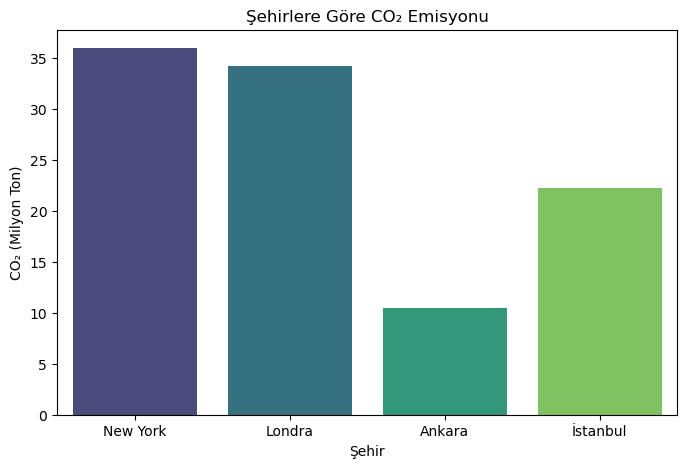

In [5]:
plt.figure(figsize=(8,5))
sns.barplot(x="Şehir", y="CO2_Emisyonu_(Milyon_Ton)", data=cities_df, palette="viridis")
plt.title("Şehirlere Göre CO₂ Emisyonu")
plt.ylabel("CO₂ (Milyon Ton)")
plt.xlabel("Şehir")
plt.show()


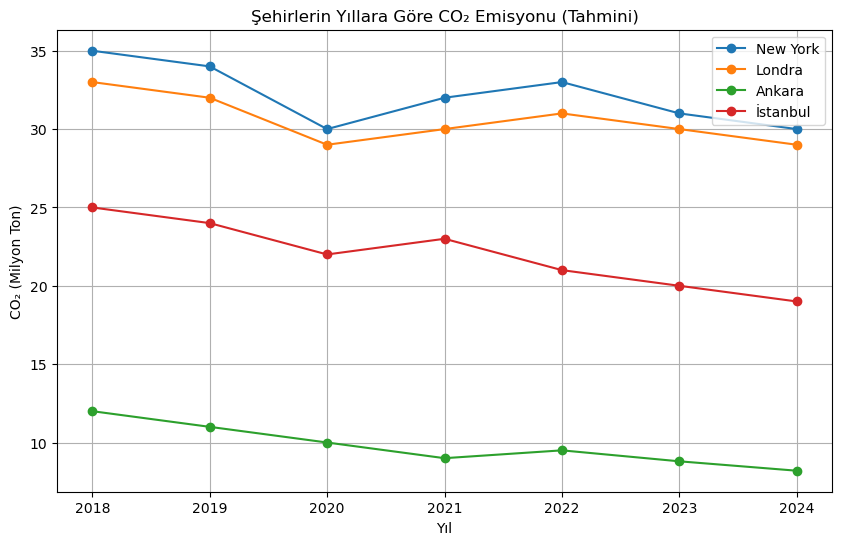

In [6]:
trend = {
    "Yıl": [2018, 2019, 2020, 2021, 2022, 2023, 2024],
    "New York": [35, 34, 30, 32, 33, 31, 30],
    "Londra": [33, 32, 29, 30, 31, 30, 29],
    "Ankara": [12, 11, 10, 9, 9.5, 8.8, 8.2],
    "İstanbul": [25, 24, 22, 23, 21, 20, 19]
}
df_trend = pd.DataFrame(trend)

plt.figure(figsize=(10,6))
for city in ["New York", "Londra", "Ankara", "İstanbul"]:
    plt.plot(df_trend["Yıl"], df_trend[city], marker="o", label=city)

plt.title("Şehirlerin Yıllara Göre CO₂ Emisyonu (Tahmini)")
plt.xlabel("Yıl")
plt.ylabel("CO₂ (Milyon Ton)")
plt.legend()
plt.grid(True)
plt.show()
